In [15]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [16]:
# --------------------------------------------------
# STEP 1: LOAD AND PREPROCESS DATA
# --------------------------------------------------

# Load dataset
data = pd.read_csv("twitter_dataset.csv")

# Display dataset
print(data.head())

# Select tweet text
tweets = data['Text'].dropna().astype(str)

# Convert tweets into words
def preprocess_text(text):

    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove mentions
    text = re.sub(r'@\w+', ' ', text)

    # Remove hashtag symbol
    text = text.replace('#', '')

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Tokenization
    words = text.split()

    # Remove stop words
    words = [
        word for word in words
        if word not in ENGLISH_STOP_WORDS
    ]

    return words


# Preprocess tweets
sentences = [
    preprocess_text(tweet)
    for tweet in tweets
]

# Remove empty sentences
sentences = [
    sentence for sentence in sentences
    if len(sentence) > 0
]

print("Total Tweets:", len(sentences))
print("Sample Tokenized Tweets:")
print(sentences[:5])

   Tweet_ID        Username  \
0         1         julie81   
1         2   richardhester   
2         3  williamsjoseph   
3         4     danielsmary   
4         5      carlwarren   

                                                Text  Retweets  Likes  \
0  Party least receive say or single. Prevent pre...         2     25   
1  Hotel still Congress may member staff. Media d...        35     29   
2  Nice be her debate industry that year. Film wh...        51     25   
3  Laugh explain situation career occur serious. ...        37     18   
4  Involve sense former often approach government...        27     80   

             Timestamp  
0  2023-01-30 11:00:51  
1  2023-01-02 22:45:58  
2  2023-01-18 11:25:19  
3  2023-04-10 22:06:29  
4  2023-01-24 07:12:21  
Total Tweets: 10000
Sample Tokenized Tweets:
[['party', 'receive', 'say', 'single', 'prevent', 'prevent', 'husband', 'affect', 'cup', 'style', 'evening', 'protect', 'effect', 'stage', 'perform', 'possible', 'try', 'tax', 'sh

In [17]:
# --------------------------------------------------
# STEP 2: TRAIN CBOW WORD2VEC MODEL
# --------------------------------------------------

model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=0,
    epochs=10
)

print("CBOW Word2Vec Model Trained Successfully")

# Display vocabulary size
print("Vocabulary Size:", len(model.wv))

CBOW Word2Vec Model Trained Successfully
Vocabulary Size: 763


In [18]:
# --------------------------------------------------
# STEP 3: EXTRACT WORD EMBEDDINGS
# --------------------------------------------------

# Get word vector
word = model.wv.index_to_key[0]

word_vector = model.wv[word]

print("Word:", word)

print("Word Vector:")
print(word_vector)

print("Vector Shape:", word_vector.shape)

Word: hard
Word Vector:
[-0.08040991  0.17074211  0.1245909   0.10569459 -0.04410108 -0.22068095
 -0.10408442  0.2644175  -0.06188989 -0.02159779 -0.11315684 -0.12401964
  0.01624483  0.02945977  0.02297565 -0.06490938 -0.05467245 -0.08174971
 -0.07222196 -0.1665618   0.04287219  0.11663611  0.04394387 -0.03600959
 -0.12157644 -0.03543836 -0.25649098 -0.12877402 -0.03884095  0.12482913
  0.24329513  0.18722393 -0.02135851  0.0569514  -0.1336247   0.16808264
 -0.13113487 -0.3133491  -0.08586544 -0.24689443 -0.03503016  0.0051381
  0.03013199 -0.06202074  0.05593427 -0.06523248 -0.09598126  0.08334361
  0.02148874 -0.03056698  0.00064483 -0.14670035 -0.10380205 -0.00685758
 -0.18966866  0.10034923  0.14693756 -0.14332812 -0.20130643  0.07582425
  0.07017965  0.11877163 -0.25632158 -0.10058928 -0.2285823   0.02100962
  0.05705583  0.02885704 -0.12711664 -0.09272737 -0.02978702 -0.07014628
  0.09748839 -0.15323974  0.02066016  0.08837537 -0.02635361 -0.1673276
 -0.0460965   0.05350345 -0.0

In [19]:
# --------------------------------------------------
# STEP 4: FIND SIMILAR WORDS
# --------------------------------------------------

# Select a word from vocabulary
word = model.wv.index_to_key[0]

print("Input Word:", word)

# Find most similar words
similar_words = model.wv.most_similar(
    word,
    topn=5
)

print("Most Similar Words:")

for w, score in similar_words:
    print(w, ":", score)

Input Word: hard
Most Similar Words:
study : 0.9764106273651123
task : 0.9757595658302307
skin : 0.9748724699020386
artist : 0.9742662310600281
west : 0.9737455248832703


In [20]:
# --------------------------------------------------
# STEP 5: CALCULATE WORD SIMILARITY
# --------------------------------------------------

# Select two words from vocabulary
word1 = model.wv.index_to_key[0]
word2 = model.wv.index_to_key[1]

similarity = model.wv.similarity(
    word1,
    word2
)

print("Word 1:", word1)
print("Word 2:", word2)

print("Similarity Score:", similarity)

Word 1: hard
Word 2: tax
Similarity Score: 0.95365745


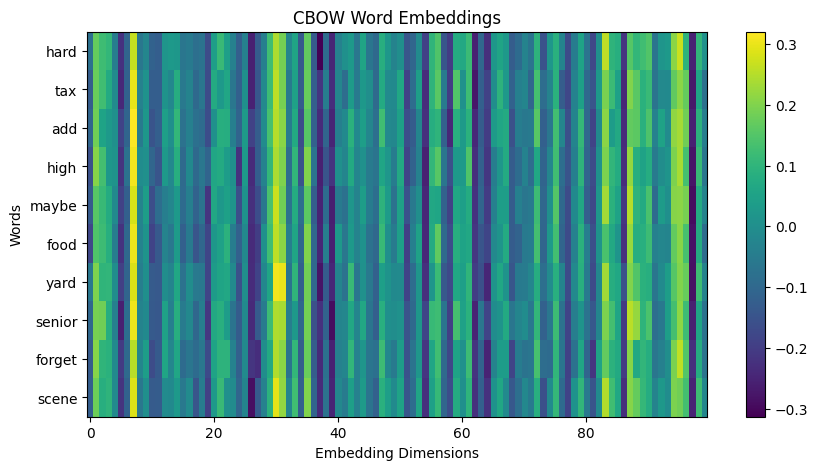

In [21]:
# --------------------------------------------------
# STEP 6: VISUALIZE WORD EMBEDDINGS
# --------------------------------------------------

# Select first 10 words
words = model.wv.index_to_key[:10]

# Get their vectors
vectors = np.array([
    model.wv[word]
    for word in words
])

# Plot embeddings
plt.figure(figsize=(10,5))

plt.imshow(vectors, aspect='auto', cmap='viridis')

plt.colorbar()

plt.yticks(range(len(words)), words)

plt.title("CBOW Word Embeddings")

plt.xlabel("Embedding Dimensions")

plt.ylabel("Words")

plt.show()

In [22]:
# --------------------------------------------------
# STEP 7: DISPLAY MODEL INFORMATION
# --------------------------------------------------

print("Total Vocabulary:", len(model.wv))

print("\nFirst 20 Words:")

print(model.wv.index_to_key[:20])

print("\nEmbedding Dimension:")

print(model.vector_size)

Total Vocabulary: 763

First 20 Words:
['hard', 'tax', 'add', 'high', 'maybe', 'food', 'yard', 'senior', 'forget', 'scene', 'success', 'man', 'young', 'job', 'edge', 'boy', 'agree', 'exactly', 'check', 'teach']

Embedding Dimension:
100


In [23]:
# --------------------------------------------------
# STEP 8: SAVE CBOW MODEL
# --------------------------------------------------

model.save("twitter_cbow.model")

print("CBOW Model Saved Successfully")

# Load saved model
loaded_model = Word2Vec.load("twitter_cbow.model")

print("CBOW Model Loaded Successfully")

CBOW Model Saved Successfully
CBOW Model Loaded Successfully
